# Trabalho Final - notebook base do projeto da Ana Maria

In [1]:
# Bibliotecas usadas na análise: pandas para manipular os dados,
# matplotlib e seaborn para os gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Pergunta de pesquisa

#### **A dependência de ferramentas de inteligência artificial está associada a mais burnout entre estudantes?**

(nível de dependência de IA, horas diárias de uso de IA, nível de burnout, horas de sono)

--- **Aviso importante sobre a natureza dos dados:** o conjunto de dados usado neste trabalho
(*AI Dependency, Career Anxiety, and Student Burnout*, Kaggle, licença MIT) é declarado pelo próprio
autor como **sintético**: são 15.000 registros de estudantes gerados por um modelo de traços latentes
com ruído controlado, e os dados faltantes foram **inseridos de propósito** ("missing_data_injected": true,
no arquivo de metadados do dataset). Ou seja, os estudantes deste arquivo não existem de verdade. Os
resultados deste notebook devem ser lidos como um **exercício de técnica de análise**, não como uma
conclusão sobre estudantes reais.

In [2]:
# Carrega o dataset a partir do zip (contém um único CSV) e mostra as primeiras linhas
df = pd.read_csv("../datasets/ana_maria/ai_dependency_career_anxiety_students.zip", compression='zip')

df.head()

,student_id,age,gender,degree_type,stream,year_of_study,college_tier,urban_or_rural,daily_ai_tool_usage_hrs,primary_ai_tools_used,...,daily_study_hours,self_learning_hours_per_week,skill_development_courses_taken,social_media_hrs_per_day,sleep_hours,stress_level,burnout_score,motivation_score,seeks_career_counseling,overall_career_readiness_score
0,STU_00001,25,Male,B.Tech/B.E.,Engineering (Non-CS),3,Tier 3,Rural,0.3,Perplexity,...,3.5,8.7,2,1.5,8.5,1,3,6,0.0,9.09
1,STU_00002,20,Female,B.Tech/B.E.,Engineering (Non-CS),4,Tier 3,Urban,1.9,ChatGPT,...,2.4,8.2,3,4.2,8.3,4,5,3,0.0,6.03
2,STU_00003,25,Female,MBA,CS/IT,1,Tier 3,Urban,3.6,Gemini,...,2.3,16.4,1,2.3,7.0,5,9,3,1.0,6.68
3,STU_00004,23,Male,B.Tech/B.E.,CS/IT,1,Tier 1,Urban,4.1,GitHub Copilot,...,7.7,15.0,3,2.6,7.2,6,6,6,0.0,7.71
4,STU_00005,22,Female,MBA,CS/IT,1,Tier 1,Urban,3.4,ChatGPT,...,2.4,1.1,2,1.9,8.0,3,5,4,0.0,4.64


In [3]:
df.columns

Index(['student_id', 'age', 'gender', 'degree_type', 'stream', 'year_of_study',
       'college_tier', 'urban_or_rural', 'daily_ai_tool_usage_hrs',
       'primary_ai_tools_used', 'uses_ai_for_assignments',
       'ai_replaces_own_thinking_score', 'ai_dependency_score',
       'placement_anxiety_score', 'fear_of_job_loss_to_ai',
       'career_clarity_score', 'internship_experience',
       'weekly_job_application_count', 'resume_confidence_score',
       'interview_anxiety_score', 'daily_study_hours',
       'self_learning_hours_per_week', 'skill_development_courses_taken',
       'social_media_hrs_per_day', 'sleep_hours', 'stress_level',
       'burnout_score', 'motivation_score', 'seeks_career_counseling',
       'overall_career_readiness_score'],
      dtype='object')

## Classificação das variáveis associadas à pergunta de pesquisa

In [4]:
# Nível de dependência de IA (pontuação composta de comportamento)
sorted(df["ai_dependency_score"].unique())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10)]

A variável **ai_dependency_score** é **numérica discreta** (pontuação composta) e varia de 1 a 10
no dataset.

In [5]:
# Horas por dia usando ferramentas de IA generativa
df["daily_ai_tool_usage_hrs"].describe()

count    15000.000000
mean         2.013893
std          1.735977
min          0.000000
25%          0.400000
50%          1.800000
75%          3.200000
max          8.000000
Name: daily_ai_tool_usage_hrs, dtype: float64

A variável **daily_ai_tool_usage_hrs** é **numérica contínua** (horas por dia) e varia de 0.0 a
8.0 no dataset.

In [6]:
# Nível de burnout (esgotamento acadêmico e distanciamento emocional) - variável-alvo da pergunta
sorted(df["burnout_score"].unique())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10)]

A variável **burnout_score** é **numérica discreta** (nota autorreferida) e varia de 1 a 10 no
dataset.

In [7]:
# Horas de sono por noite
df["sleep_hours"].describe()

count    14797.000000
mean         6.993364
std          1.004809
min          4.000000
25%          6.300000
50%          7.000000
75%          7.700000
max         10.000000
Name: sleep_hours, dtype: float64

A variável **sleep_hours** é **numérica contínua** (horas por noite) e varia de 4.0 a 10.0 no
dataset.

## Verificando a qualidade dos dados

In [8]:
# Verificando se há duplicatas
df.duplicated().sum()

np.int64(0)

**Conclusão 1:** não há linhas duplicadas no dataset analisado.

In [9]:
# Verificando se há valores faltantes (soma e porcentagem por coluna)
dados_faltantes_soma = df.isnull().sum()
dados_faltantes_porc = df.isnull().mean() * 100

df_dados_faltantes = pd.DataFrame({
    "Dados faltantes (soma)": dados_faltantes_soma,
    "Dados faltantes (porcentagem)": dados_faltantes_porc,
})
df_dados_faltantes[df_dados_faltantes["Dados faltantes (soma)"] > 0]

,Dados faltantes (soma),Dados faltantes (porcentagem)
primary_ai_tools_used,3215,21.433333
self_learning_hours_per_week,233,1.553333
social_media_hrs_per_day,210,1.400000
sleep_hours,203,1.353333
seeks_career_counseling,220,1.466667


**Conclusão 2:** há valores faltantes em 5 das 30 colunas: `primary_ai_tools_used` (3.215, 21.43%), `self_learning_hours_per_week` (233, 1.55%), `seeks_career_counseling` (220, 1.47%), `social_media_hrs_per_day` (210, 1.40%) e `sleep_hours` (203, 1.35%). Das quatro variáveis da pergunta de pesquisa, só `sleep_hours` tem faltantes. Como o autor declara que os faltantes foram inseridos de propósito, não há um motivo real por trás deles para investigar.

## Limpeza do conjunto de dados

In [10]:
# Remove apenas as linhas sem horas de sono, que é a única variável da pergunta de pesquisa
# com dados faltantes. As outras colunas com faltantes não entram na análise.
df = df.dropna(subset=["sleep_hours"])

df.shape

(14797, 30)

**Conclusão 3:** removi as 203 linhas sem `sleep_hours` (1.35% do total), ficando com 14.797 estudantes. As demais colunas com faltantes não são usadas na análise, então foram mantidas como estão. Não havia duplicatas para remover.

## Estatística descritiva

Utiliza as variáveis numéricas identificadas no início do trabalho para calcular estatísticas
descritivas pertinentes à pergunta de pesquisa.

In [11]:
df[["ai_dependency_score", "daily_ai_tool_usage_hrs", "burnout_score", "sleep_hours"]].describe()

,ai_dependency_score,daily_ai_tool_usage_hrs,burnout_score,sleep_hours
count,14797.000000,14797.000000,14797.000000,14797.000000
mean,4.538893,2.013523,5.474083,6.993364
std,2.315551,1.737050,2.066895,1.004809
min,1.000000,0.000000,1.000000,4.000000
25%,3.000000,0.400000,4.000000,6.300000
50%,4.000000,1.800000,5.000000,7.000000
75%,6.000000,3.200000,7.000000,7.700000
max,10.000000,8.000000,10.000000,10.000000


In [12]:
# "ai_dependency_score" vai de 1 a 10. Para comparar grupos de estudantes, dividimos a escala
# em três faixas de mesma largura de pontuação: Baixa (1 a 3), Média (4 a 7) e Alta (8 a 10).
# Não existe um corte oficial de "dependência de IA", então mostramos os limites usados.
df["faixa_dependencia"] = pd.cut(
    df["ai_dependency_score"],
    bins=[0, 3, 7, 10],
    labels=["Baixa (1-3)", "Média (4-7)", "Alta (8-10)"],
)

df["faixa_dependencia"].value_counts().sort_index()

faixa_dependencia
Baixa (1-3)    5336
Média (4-7)    7699
Alta (8-10)    1762
Name: count, dtype: int64

In [13]:
# Calcula o burnout médio e as horas de sono médias em cada faixa de dependência de IA
df_med_dep = df.groupby("faixa_dependencia", observed=True)[["burnout_score", "sleep_hours"]].mean()

print("Burnout médio e sono médio por faixa de dependência de IA:")
print(df_med_dep)

Burnout médio e sono médio por faixa de dependência de IA:
                   burnout_score  sleep_hours
faixa_dependencia                            
Baixa (1-3)             4.657609     6.994771
Média (4-7)             5.738148     6.994337
Alta (8-10)             6.792849     6.984847


**Conclusão 4:** o burnout médio cresce de forma consistente com a dependência de IA: 4.66 na faixa Baixa (5.336 estudantes), 5.74 na Média (7.699) e 6.79 na Alta (1.762), uma diferença de 2.1 pontos numa escala de 1 a 10 entre os extremos. Já as horas de sono são praticamente iguais nas três faixas (6.98 a 6.99 horas), ou seja, a dependência de IA não aparece associada ao sono.

In [14]:
# Verificamos também a correlação linear entre as variáveis numéricas originais
# (sem categorizar), para checar a associação por outro caminho
df[["ai_dependency_score", "daily_ai_tool_usage_hrs", "burnout_score", "sleep_hours"]].corr()

,ai_dependency_score,daily_ai_tool_usage_hrs,burnout_score,sleep_hours
ai_dependency_score,1.000000,0.716073,0.368907,0.001011
daily_ai_tool_usage_hrs,0.716073,1.000000,0.256278,-0.004621
burnout_score,0.368907,0.256278,1.000000,-0.172022
sleep_hours,0.001011,-0.004621,-0.172022,1.000000


**Conclusão 5:** a correlação confirma o padrão: `burnout_score` tem correlação positiva moderada com `ai_dependency_score` (0.37) e mais fraca com `daily_ai_tool_usage_hrs` (0.26). As duas medidas de IA são fortemente correlacionadas entre si (0.72), o que faz sentido, já que quem usa mais horas tende a depender mais. A correlação de `sleep_hours` com as medidas de IA é praticamente zero (0.00), mas o sono tem uma correlação negativa fraca com o burnout (-0.17): quem tem mais burnout dorme um pouco menos, independentemente do uso de IA.

**Conclusão final (síntese):** neste conjunto de dados sintético de 14.797 estudantes, **mais dependência de IA está associada a mais burnout**, com uma diferença clara entre as faixas e uma correlação moderada. A dependência medida pelo comportamento (`ai_dependency_score`) se relaciona mais com o burnout do que as horas de uso em si. O sono, por outro lado, não varia com a dependência de IA. Essa associação não indica causa: pode ser que estudantes já esgotados recorram mais à IA. E, como os dados foram gerados por um modelo, o padrão reflete as regras usadas pelo autor para gerar os dados, não necessariamente o comportamento de estudantes reais.

## Análise Exploratória

(apenas um "gostinho" no workshop de 29/08 pois isso será explorado no próximo encontro)

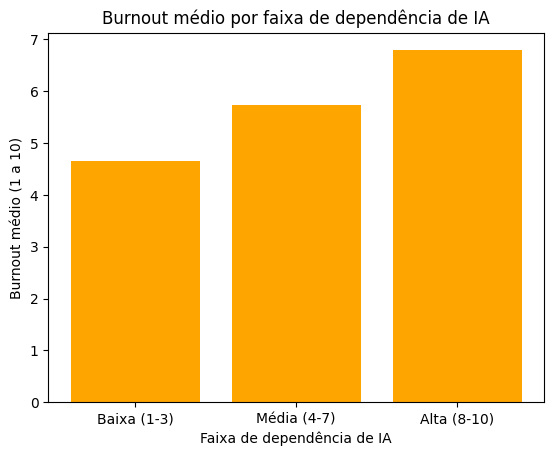

In [15]:
# Gráfico de barras: burnout médio por faixa de dependência de IA
plt.bar(df_med_dep.index.astype(str), df_med_dep["burnout_score"], color="orange")
plt.title("Burnout médio por faixa de dependência de IA")
plt.xlabel("Faixa de dependência de IA")
plt.ylabel("Burnout médio (1 a 10)")
plt.show()

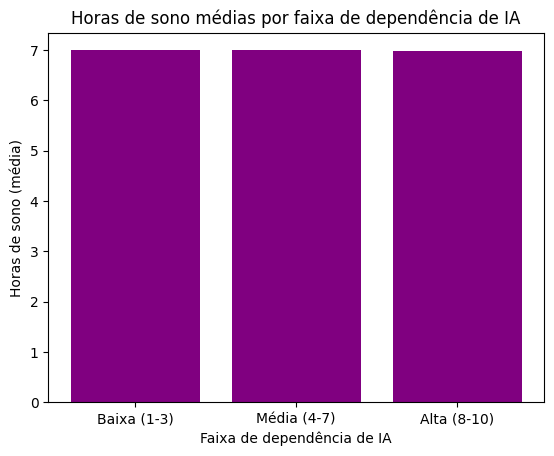

In [16]:
# Gráfico de barras: sono médio por faixa de dependência de IA
plt.bar(df_med_dep.index.astype(str), df_med_dep["sleep_hours"], color="purple")
plt.title("Horas de sono médias por faixa de dependência de IA")
plt.xlabel("Faixa de dependência de IA")
plt.ylabel("Horas de sono (média)")
plt.show()